In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
from google.colab import drive

# This will ask for permission to connect your Google Drive
print("Connecting to Google Drive...")
drive.mount('/content/drive')

# Create a destination folder in Colab
!mkdir -p /content/dataset

# Unzip your data from Drive to the Colab folder. This will be fast.
# Make sure your zip file is named celeba.zip and is in the main "My Drive" folder.
print("\nUnzipping dataset...")
!unzip -q "/content/drive/My Drive/celeba.zip" -d "/content/dataset/"
print("Dataset successfully unzipped!")

Connecting to Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Unzipping dataset...
Dataset successfully unzipped!


In [ ]:
import os
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from lime import lime_image
from skimage.segmentation import mark_boundaries
import matplotlib.pyplot as plt

# --- Device ---
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# --- Dataset class (subset of test images) ---
class CelebADataset(Dataset):
    def __init__(self, dataset_root, transform=None, partition='test', subset=None):
        self.dataset_root = dataset_root
        self.transform = transform
        attr_path = os.path.join(dataset_root, "list_attr_celeba.csv")
        part_path = os.path.join(dataset_root, "list_eval_partition.csv")
        self.attrs = pd.read_csv(attr_path, index_col=0)
        part_df = pd.read_csv(part_path)
        part_map = {'train': 0, 'val': 1, 'test': 2}
        self.images = part_df[part_df['partition'] == part_map[partition]]['image_id'].tolist()
        if subset: self.images = self.images[:subset]

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.dataset_root, "img_align_celeba", "img_align_celeba", img_name)
        image = Image.open(img_path).convert("RGB")
        if self.transform: image = self.transform(image)
        labels = self.attrs.loc[img_name].values.astype('int')
        labels[labels == -1] = 0
        return image, torch.tensor(labels, dtype=torch.float)

# --- Transform ---
IMAGE_SIZE = 224
data_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5,0.5,0.5],[0.5,0.5,0.5])
])

# --- Dataset & DataLoader ---
dataset_root = "/content/dataset"
test_subset = 100   # number of images to explain
test_dataset = CelebADataset(dataset_root, transform=data_transform, partition='test', subset=test_subset)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

# --- Load your trained model ---
model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 40)  # 40 CelebA attributes
model.load_state_dict(torch.load("/content/drive/My Drive/celeba_scratch_final.pth", map_location=device))
model.to(device)
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:
import os
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from tqdm import tqdm

dataset_root = r"/content/dataset"

class CelebADataset(Dataset):
    def __init__(self, dataset_root, transform=None, partition='train', subset=None):
        self.dataset_root = dataset_root
        self.transform = transform
        attr_path = os.path.join(dataset_root, "list_attr_celeba.csv")
        part_path = os.path.join(dataset_root, "list_eval_partition.csv")
        self.attrs = pd.read_csv(attr_path, index_col=0)
        part_df = pd.read_csv(part_path)
        part_map = {'train': 0, 'val': 1, 'test': 2}
        self.images = part_df[part_df['partition'] == part_map[partition]]['image_id'].tolist()
        if subset: self.images = self.images[:subset]

    def __len__(self): return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.dataset_root, "img_align_celeba", "img_align_celeba", img_name)
        image = Image.open(img_path).convert("RGB")
        if self.transform: image = self.transform(image)
        labels = self.attrs.loc[img_name].values.astype('int')
        labels[labels == -1] = 0
        return image, torch.tensor(labels, dtype=torch.float)

# --- Training Settings ---
IMAGE_SIZE = 224
TRAIN_SUBSET = None
VAL_SUBSET = None
NUM_EPOCHS = 8
BATCH_SIZE = 64
# ---------------------------

data_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5,0.5,0.5],[0.5,0.5,0.5])
])

train_dataset = CelebADataset(dataset_root, transform=data_transform, partition='train', subset=TRAIN_SUBSET)
val_dataset   = CelebADataset(dataset_root, transform=data_transform, partition='val', subset=VAL_SUBSET)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

print(f"Starting training plan...")
print(f"Train samples: {len(train_dataset)}, Validation samples: {len(val_dataset)}\n")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}\n")

model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 40)
model = model.to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

for epoch in range(NUM_EPOCHS):
    model.train()
    running_loss = 0.0
    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]"):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
    epoch_loss = running_loss / len(train_loader.dataset)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]"):
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
    epoch_val_loss = val_loss / len(val_loader.dataset)

    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}], Train Loss: {epoch_loss:.4f}, Val Loss: {epoch_val_loss:.4f}")

    # Save a checkpoint after each epoch
    CHECKPOINT_PATH = f"/content/drive/My Drive/celeba_scratch_epoch_{epoch+1}.pth"
    torch.save(model.state_dict(), CHECKPOINT_PATH)
    print(f"Checkpoint saved to: {CHECKPOINT_PATH}")

print("\nTraining finished!")

# Save the final model with a clear name
FINAL_SAVE_PATH = "/content/drive/My Drive/celeba_scratch_final.pth"
torch.save(model.state_dict(), FINAL_SAVE_PATH)
print(f"Final model saved permanently to your Google Drive at: {FINAL_SAVE_PATH}")

Starting training plan...
Train samples: 162770, Validation samples: 19867

Using device: cuda



Epoch 1/8 [Val]: 100%|██████████| 311/311 [01:09<00:00,  4.50it/s]


Epoch [1/8], Train Loss: 0.2806, Val Loss: 0.2347
Checkpoint saved to: /content/drive/My Drive/celeba_scratch_epoch_1.pth


Epoch 2/8 [Val]: 100%|██████████| 311/311 [01:10<00:00,  4.41it/s]


Epoch [2/8], Train Loss: 0.2200, Val Loss: 0.2116
Checkpoint saved to: /content/drive/My Drive/celeba_scratch_epoch_2.pth


...

Epoch [6/8], Train Loss: 0.1730, Val Loss: 0.2110
Checkpoint saved to: /content/drive/My Drive/celeba_scratch_epoch_6.pth


Epoch 7/8 [Val]: 100%|██████████| 311/311 [01:06<00:00,  4.67it/s]


Epoch [7/8], Train Loss: 0.1607, Val Loss: 0.2175
Checkpoint saved to: /content/drive/My Drive/celeba_scratch_epoch_7.pth


Epoch 8/8 [Val]: 100%|██████████| 311/311 [01:09<00:00,  4.45it/s]


Epoch [8/8], Train Loss: 0.1467, Val Loss: 0.2197
Checkpoint saved to: /content/drive/My Drive/celeba_scratch_epoch_8.pth

Training finished!
Final model saved permanently to your Google Drive at: /content/drive/My Drive/celeba_scratch_final.pth


Successfully loaded model from: /content/drive/My Drive/celeba_scratch_epoch_4.pth


Calculating Accuracy on Test Set:   0%|          | 0/16 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
Calculating Accuracy on Test Set: 100%|██████████| 16/16 [04:26<00:00, 16.68s/it]



## Overall Model Accuracy on the Test Set: 90.67%

## Predictions for a single test image:


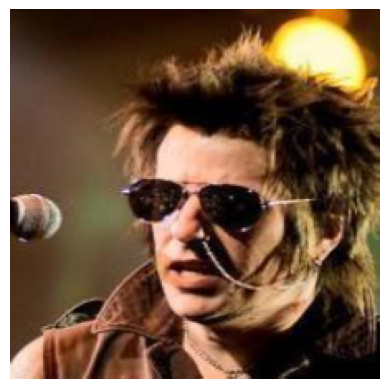


Predicted Attributes:
- Eyeglasses
- Male
- Mouth_Slightly_Open
- No_Beard
- Young

True Attributes:
- Eyeglasses
- Male
- No_Beard
- Straight_Hair
- Wavy_Hair
- Wearing_Necklace
- Young


In [ ]:
MODEL_PATH = "/content/drive/My Drive/celeba_scratch_epoch_4.pth"

model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 40)

# FIXED: Added map_location to the torch.load call
model.load_state_dict(torch.load(MODEL_PATH, map_location=torch.device('cpu')))

model = model.to(device)
model.eval()

print(f"Successfully loaded model from: {MODEL_PATH}")

# QUANTITATIVE EVALUATION (ACCURACY ON TEST SET) ---
# Using a subset for a faster run on CPU
test_dataset = CelebADataset(dataset_root, transform=data_transform, partition='test', subset=1000)
test_loader  = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

total_correct = 0
total_labels = 0
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Calculating Accuracy on Test Set"):
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        predicted = (torch.sigmoid(outputs) > 0.5).float()
        total_correct += (predicted == labels).sum().item()
        total_labels += labels.numel()

accuracy = 100 * total_correct / total_labels
print(f"\n## Overall Model Accuracy on the Test Set: {accuracy:.2f}%\n")

# QUALITATIVE EVALUATION (PREDICT ON ONE IMAGE) ---
image, labels = test_dataset[10]
image_for_plot = image.permute(1, 2, 0).numpy() * 0.5 + 0.5 # Un-normalize for display

with torch.no_grad():
    output = model(image.unsqueeze(0).to(device))
    probabilities = torch.sigmoid(output)
    predictions = (probabilities > 0.5).float().squeeze()

print("## Predictions for a single test image:")
plt.imshow(image_for_plot)
plt.axis('off')
plt.show()

print("\nPredicted Attributes:")
for i, val in enumerate(predictions):
    if val.item() == 1:
        print(f"- {test_dataset.attribute_names[i]}")

print("\nTrue Attributes:")
for i, val in enumerate(labels):
    if val.item() == 1:
        print(f"- {test_dataset.attribute_names[i]}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Successfully loaded model from: /content/drive/My Drive/celeba_scratch_epoch_4.pth

Running LIME analysis... (this will take 5-15 minutes on CPU)


  0%|          | 0/1000 [00:00<?, ?it/s]

Analysis complete.

Generating saliency map for the top predicted attribute: 'Wearing_Hat'

Saved LIME saliency map to 'lime_saliency_map.png'


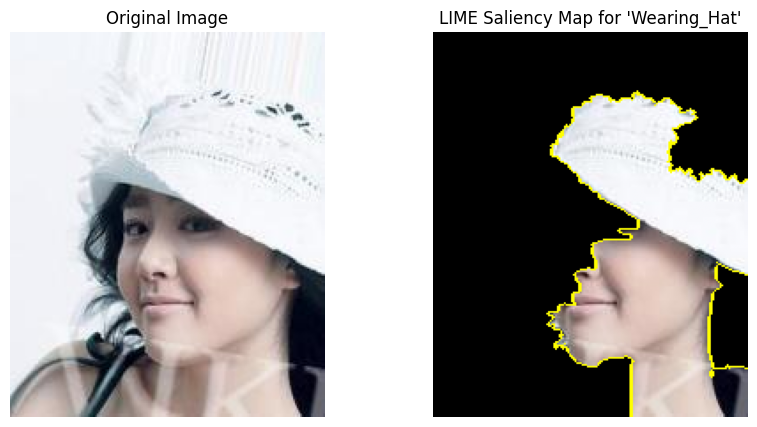

In [ ]:
import os
import pandas as pd
import torch
import torch.nn as nn
from torchvision import models, transforms
from torch.utils.data import Dataset
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# installing and import explainability libraries
!pip install lime -q
from lime import lime_image
from skimage.segmentation import mark_boundaries

# DEFINE CLASSES AND VARIABLES
# Define the path to your unzipped data in Colab
dataset_root = r"/content/dataset"
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# The Dataset class is needed to load and preprocess a specific image
class CelebADataset(Dataset):
    def __init__(self, dataset_root, transform=None, partition='train', subset=None):
        self.dataset_root = dataset_root
        self.transform = transform
        attr_path = os.path.join(dataset_root, "list_attr_celeba.csv")
        part_path = os.path.join(dataset_root, "list_eval_partition.csv")
        self.attrs = pd.read_csv(attr_path, index_col=0)
        self.attribute_names = self.attrs.columns.tolist()
        part_df = pd.read_csv(part_path)
        part_map = {'train': 0, 'val': 1, 'test': 2}
        self.images = part_df[part_df['partition'] == part_map[partition]]['image_id'].tolist()
        if subset: self.images = self.images[:subset]

    def __len__(self): return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.dataset_root, "img_align_celeba", "img_align_celeba", img_name)
        image_pil = Image.open(img_path).convert("RGB")
        # For LIME, we primarily need the numpy version of the image
        image_np = np.array(image_pil)
        return image_np, self.attribute_names

# The same data transforms used during training are needed for the prediction function
data_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5,0.5,0.5],[0.5,0.5,0.5])
])

# BEST TRAINED MODEL
MODEL_PATH = "/content/drive/My Drive/celeba_scratch_epoch_4.pth"

model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 40)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model = model.to(device)
model.eval()

print(f"Successfully loaded model from: {MODEL_PATH}\n")

# RUN THE LIME EXPLAINER

# This function allows LIME to get predictions from complex ResNet-50 model
def predict_fn(numpy_images):
    images = torch.stack([data_transform(Image.fromarray(img)) for img in numpy_images], dim=0)
    images = images.to(device)
    with torch.no_grad():
        logits = model(images)
        probs = torch.sigmoid(logits)
    return probs.cpu().numpy()

# Load the test dataset to get an image to explain
test_dataset = CelebADataset(dataset_root, transform=data_transform, partition='test')
image_np, attribute_names = test_dataset[42] # Using the 43rd image from the test set

# Create the LIME explainer tool
explainer = lime_image.LimeImageExplainer()

print("Running LIME analysis... (this will take 5-15 minutes on CPU)")
# This is where LIME builds its temporary, simple linear model to explain the prediction
explanation = explainer.explain_instance(
    image_np,
    predict_fn,
    top_labels=3,
    hide_color=0,
    num_samples=1000
)
print("Analysis complete.")

# --- 5. GENERATE AND SAVE THE SALIENCY MAP ---
# The explanation from the simple model is visualized as a saliency map.

top_label_index = explanation.top_labels[0]
top_attribute_name = attribute_names[top_label_index]
print(f"\nGenerating saliency map for the top predicted attribute: '{top_attribute_name}'")

temp, mask = explanation.get_image_and_mask(
    top_label_index,
    positive_only=True,
    num_features=5,
    hide_rest=True
)

# Display the final output
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(image_np)
ax[0].set_title("Original Image")
ax[0].axis('off')

ax[1].imshow(mark_boundaries(temp / 255.0, mask))
ax[1].set_title(f"LIME Saliency Map for '{top_attribute_name}'")
ax[1].axis('off')

# Save the saliency map to a file. This is the output for your UI.
plt.savefig("lime_saliency_map.png")
print("\nSaved LIME saliency map to 'lime_saliency_map.png'")

plt.show()


--- Running LIME analysis for image #1 ---


  0%|          | 0/200 [00:00<?, ?it/s]


--- Running LIME analysis for image #2 ---


  0%|          | 0/200 [00:00<?, ?it/s]

Top predicted attribute: 'No_Beard'
Saved saliency map: '/content/drive/My Drive/lime_explanation_2.png'


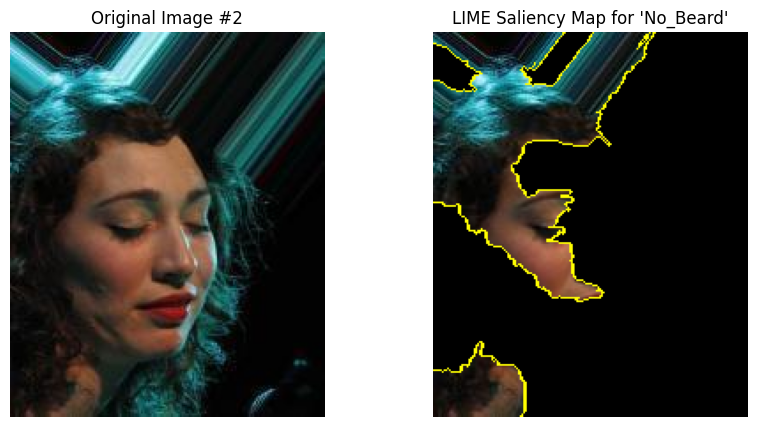


--- Running LIME analysis for image #3 ---


  0%|          | 0/200 [00:00<?, ?it/s]


--- Running LIME analysis for image #4 ---


  0%|          | 0/200 [00:00<?, ?it/s]


--- Running LIME analysis for image #5 ---


...


--- Running LIME analysis for image #7 ---


  0%|          | 0/200 [00:00<?, ?it/s]


--- Running LIME analysis for image #8 ---


  0%|          | 0/200 [00:00<?, ?it/s]

Top predicted attribute: 'No_Beard'
Saved saliency map: '/content/drive/My Drive/lime_explanation_8.png'


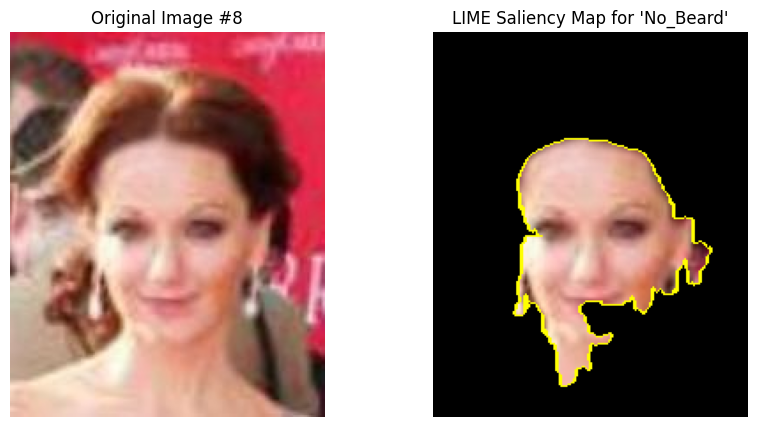


--- Running LIME analysis for image #9 ---


  0%|          | 0/200 [00:00<?, ?it/s]


--- Running LIME analysis for image #10 ---


  0%|          | 0/200 [00:00<?, ?it/s]


--- Running LIME analysis for image #11 ---


...


--- Running LIME analysis for image #59 ---


  0%|          | 0/200 [00:00<?, ?it/s]


--- Running LIME analysis for image #60 ---


  0%|          | 0/200 [00:00<?, ?it/s]

Top predicted attribute: 'Male'
Saved saliency map: '/content/drive/My Drive/lime_explanation_60.png'


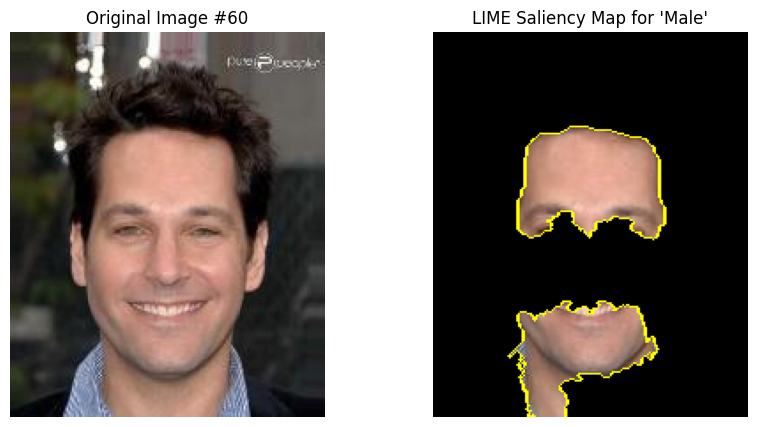


--- Running LIME analysis for image #61 ---


  0%|          | 0/200 [00:00<?, ?it/s]


--- Running LIME analysis for image #62 ---


  0%|          | 0/200 [00:00<?, ?it/s]


--- Running LIME analysis for image #63 ---


  0%|          | 0/200 [00:00<?, ?it/s]

Top predicted attribute: 'Smiling'
Saved saliency map: '/content/drive/My Drive/lime_explanation_63.png'


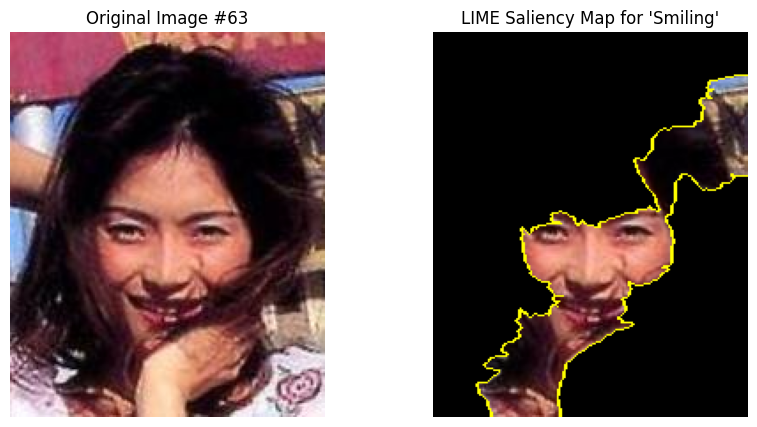


--- Running LIME analysis for image #64 ---


  0%|          | 0/200 [00:00<?, ?it/s]


--- Running LIME analysis for image #65 ---


  0%|          | 0/200 [00:00<?, ?it/s]


--- Running LIME analysis for image #66 ---


...


--- Running LIME analysis for image #84 ---


  0%|          | 0/200 [00:00<?, ?it/s]


--- Running LIME analysis for image #85 ---


  0%|          | 0/200 [00:00<?, ?it/s]

Top predicted attribute: 'No_Beard'
Saved saliency map: '/content/drive/My Drive/lime_explanation_85.png'


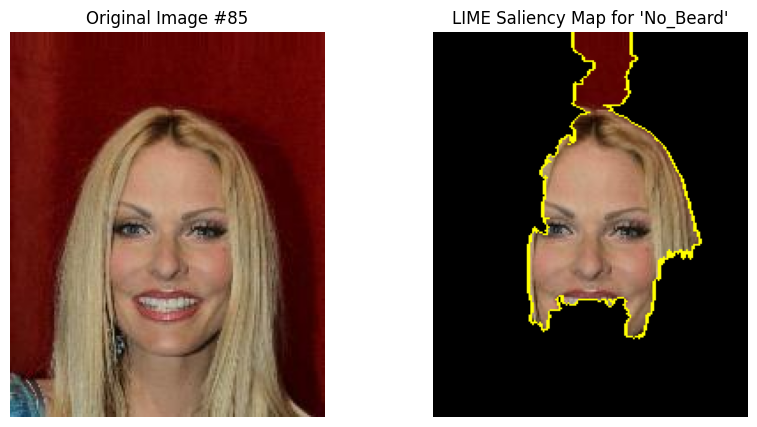


--- Running LIME analysis for image #86 ---


  0%|          | 0/200 [00:00<?, ?it/s]


--- Running LIME analysis for image #87 ---


  0%|          | 0/200 [00:00<?, ?it/s]


--- Running LIME analysis for image #88 ---


...

  0%|          | 0/200 [00:00<?, ?it/s]


--- Running LIME analysis for image #99 ---


  0%|          | 0/200 [00:00<?, ?it/s]


--- Running LIME analysis for image #100 ---


  0%|          | 0/200 [00:00<?, ?it/s]

In [ ]:
import os
import pandas as pd
import torch
import torch.nn as nn
from torchvision import models, transforms
from torch.utils.data import Dataset
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries
import random

# --- 1. SETUP ---
dataset_root = r"/content/dataset"
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

class CelebADataset(Dataset):
    def __init__(self, dataset_root, transform=None, partition='train', subset=None):
        self.dataset_root = dataset_root
        self.transform = transform
        attr_path = os.path.join(dataset_root, "list_attr_celeba.csv")
        part_path = os.path.join(dataset_root, "list_eval_partition.csv")
        self.attrs = pd.read_csv(attr_path, index_col=0)
        self.attribute_names = self.attrs.columns.tolist()
        part_df = pd.read_csv(part_path)
        part_map = {'train': 0, 'val': 1, 'test': 2}
        self.images = part_df[part_df['partition'] == part_map[partition]]['image_id'].tolist()
        if subset: self.images = self.images[:subset]

    def __len__(self): return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.dataset_root, "img_align_celeba", "img_align_celeba", img_name)
        image_pil = Image.open(img_path).convert("RGB")
        image_np = np.array(image_pil, dtype=np.uint8)  # convert to uint8
        return image_np, self.attribute_names

# Data transforms
data_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5,0.5,0.5],[0.5,0.5,0.5])
])

# --- 2. LOAD MODEL ---
MODEL_PATH = "/content/drive/My Drive/celeba_scratch_epoch_4.pth"
model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 40)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model = model.to(device)
model.eval()

# --- 3. PREDICTION FUNCTION ---
def predict_fn(numpy_images):
    images = []
    for img in numpy_images:
        if np.isnan(img).any():
            # Skip images with NaNs
            img = np.nan_to_num(img, nan=0)
        images.append(data_transform(Image.fromarray(img)))
    images = torch.stack(images, dim=0).to(device)
    with torch.no_grad():
        logits = model(images)
        probs = torch.sigmoid(logits).cpu().numpy()
        probs = np.nan_to_num(probs, nan=0.0)  # replace NaNs
    return probs

# --- 4. LOAD DATASET AND INITIALIZE LIME ---
test_dataset = CelebADataset(dataset_root, transform=data_transform, partition='test')
explainer = lime_image.LimeImageExplainer()

num_images_to_explain = 100
num_samples = 200
VISUALIZE_COUNT = 5
visualize_indices = random.sample(range(num_images_to_explain), VISUALIZE_COUNT)

# --- 5. LOOP TO GENERATE EXPLANATIONS ---
for i in range(num_images_to_explain):
    print(f"\n--- Running LIME analysis for image #{i+1} ---")
    image_np, attribute_names = test_dataset[i]

    # Skip corrupted images
    if np.isnan(image_np).any():
        print(f"Skipping image {i+1} due to NaNs.")
        continue

    # Generate explanation
    explanation = explainer.explain_instance(
        image_np,
        predict_fn,
        top_labels=3,
        hide_color=0,
        num_samples=num_samples
    )

    # Visualize only some random images
    if i in visualize_indices:
        top_label_index = explanation.top_labels[0]
        top_attribute_name = attribute_names[top_label_index]
        print(f"Top predicted attribute: '{top_attribute_name}'")

        temp, mask = explanation.get_image_and_mask(
            top_label_index,
            positive_only=True,
            num_features=5,
            hide_rest=True
        )

        fig, ax = plt.subplots(1, 2, figsize=(10, 5))
        ax[0].imshow(image_np)
        ax[0].set_title(f"Original Image #{i+1}")
        ax[0].axis('off')

        ax[1].imshow(mark_boundaries(temp / 255.0, mask))
        ax[1].set_title(f"LIME Saliency Map for '{top_attribute_name}'")
        ax[1].axis('off')

        save_path = f"/content/drive/My Drive/lime_explanation_{i+1}.png"
        plt.savefig(save_path)
        print(f"Saved saliency map: '{save_path}'")
        plt.show()

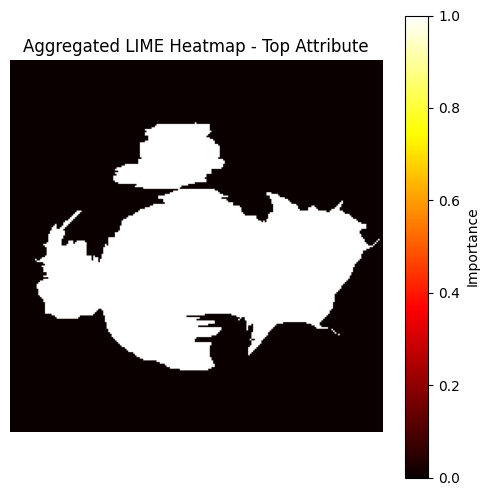

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.segmentation import mark_boundaries

# Initialize an empty accumulator
accumulated_map = np.zeros((224, 224))  # assuming images resized to 224x224

# Aggregate LIME masks
for explanation in lime_results:
    top_label_index = explanation.top_labels[0]
    temp, mask = explanation.get_image_and_mask(
        top_label_index,
        left_top_label,
        right_top_label,
        negative_only=False,
        
        positive_only=True,
        num_features=10,
        hide_rest=False
    )
    accumulated_map += mask

# Average over all images
average_heatmap = accumulated_map / len(lime_results)

# Visualize as a heatmap
plt.figure(figsize=(6,6))
plt.imshow(average_heatmap, cmap='hot')
plt.title("Aggregated LIME Heatmap - Top Attribute")
plt.axis('off')
plt.colorbar(label="Importance")
plt.show()

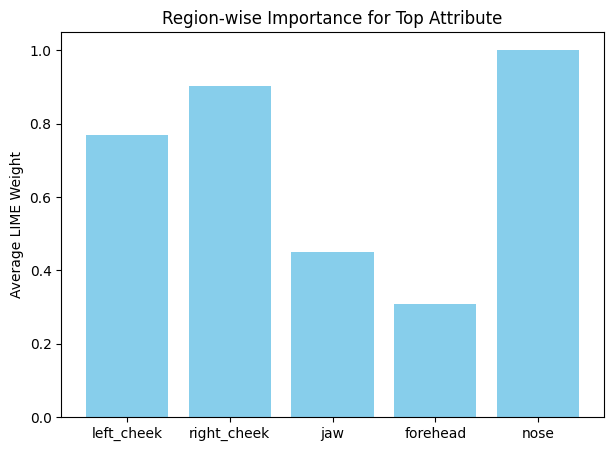

In [ ]:
# Define regions (example slices; adjust if needed)
regions = {
    'left_cheek':  (slice(80,150), slice(40,110)),
    'right_cheek': (slice(80,150), slice(110,180)),
    'jaw':         (slice(150,200), slice(60,160)),
    'forehead':    (slice(20,80), slice(60,160)),
    'nose':        (slice(100,140), slice(90,130)),
}

region_importance = {}
for name, (rows, cols) in regions.items():
    region_importance[name] = np.mean(average_heatmap[rows, cols])

# Plot bar chart
plt.figure(figsize=(7,5))
plt.bar(region_importance.keys(), region_importance.values(), color='skyblue')
plt.ylabel("Average LIME Weight")
plt.title("Region-wise Importance for Top Attribute")
plt.show()


/tmp/ipython-input-221289293.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(region_values.values(), labels=region_values.keys())


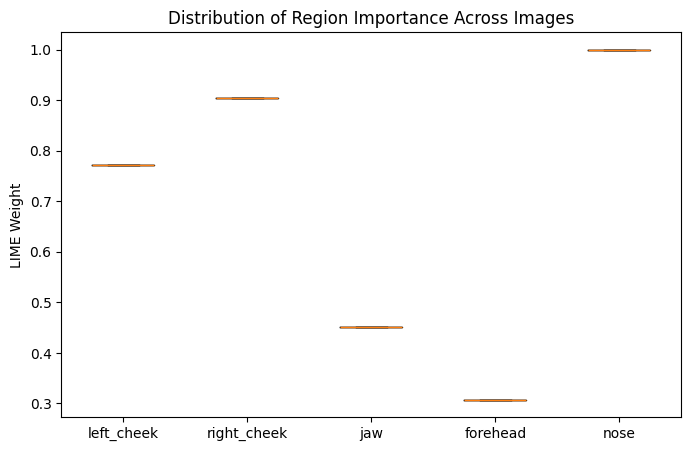

In [ ]:
# Collect per-image region values
region_values = {name: [] for name in regions.keys()}

for explanation in lime_results:
    top_label_index = explanation.top_labels[0]
    temp, mask = explanation.get_image_and_mask(
        top_label_index,
        positive_only=True,
        num_features=10,
        hide_rest=False
    )
    for name, (rows, cols) in regions.items():
        region_values[name].append(np.mean(mask[rows, cols]))

# Boxplot
plt.figure(figsize=(8,5))
plt.boxplot(region_values.values(), labels=region_values.keys())
plt.ylabel("LIME Weight")
plt.title("Distribution of Region Importance Across Images")
plt.show()


Model loaded successfully.

Running SHAP analysis using PartitionExplainer...


  0%|          | 0/254 [00:00<?, ?it/s]

PartitionExplainer explainer:  50%|█████     | 1/2 [00:00<?, ?it/s]

  0%|          | 0/254 [00:00<?, ?it/s]

PartitionExplainer explainer: 3it [02:36, 78.46s/it]


Analysis complete.

Generating SHAP plot...


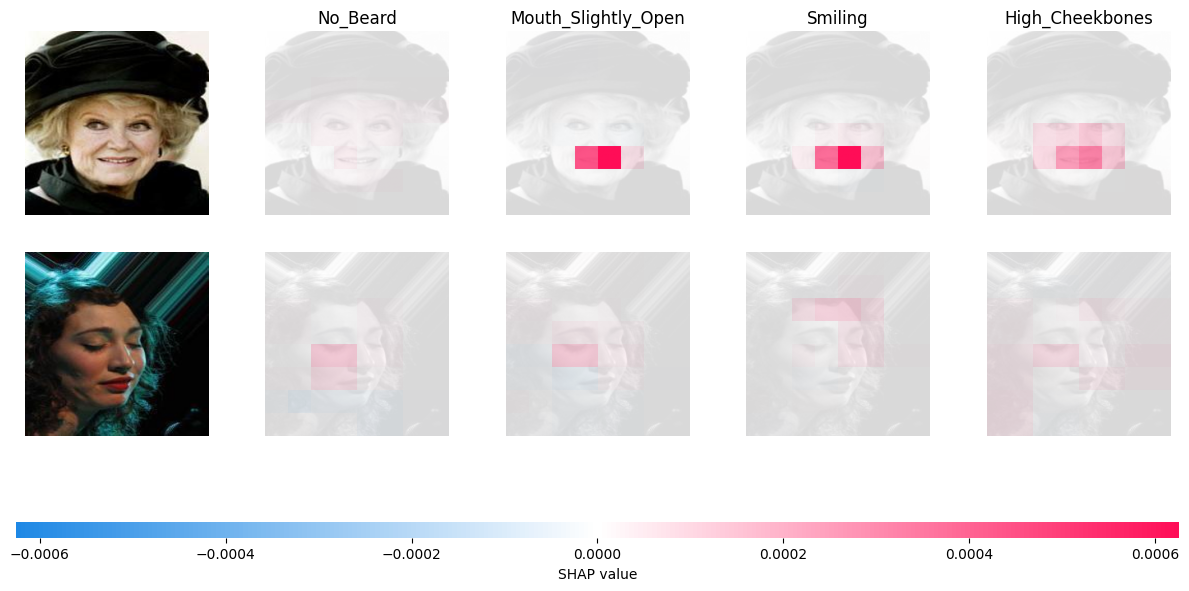

In [ ]:
# ====================================================================
# FINAL, ROBUST SHAP SCRIPT (using PartitionExplainer)
# ====================================================================

import os
import pandas as pd
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# --- 1. SETUP: Install and Import Explainability Libraries ---
!pip install shap -q
import shap

# --- 2. DEFINE CLASSES AND VARIABLES ---
# Define the path to your unzipped data in Colab
dataset_root = r"/content/dataset"
device = torch.device('cpu') # Running on CPU

# The Dataset class is needed to load and preprocess images
class CelebADataset(Dataset):
    def __init__(self, dataset_root, transform=None, partition='train', subset=None):
        self.dataset_root = dataset_root
        self.transform = transform
        attr_path = os.path.join(dataset_root, "list_attr_celeba.csv")
        part_path = os.path.join(dataset_root, "list_eval_partition.csv")
        self.attrs = pd.read_csv(attr_path, index_col=0)
        self.attribute_names = self.attrs.columns.tolist()
        part_df = pd.read_csv(part_path)
        part_map = {'train': 0, 'val': 1, 'test': 2}
        self.images = part_df[part_df['partition'] == part_map[partition]]['image_id'].tolist()
        if subset: self.images = self.images[:subset]

    def __len__(self): return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.dataset_root, "img_align_celeba", "img_align_celeba", img_name)
        image_pil = Image.open(img_path).convert("RGB")
        return image_pil

# The same data transforms used during training
data_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5,0.5,0.5],[0.5,0.5,0.5])
])

# --- 3. LOAD YOUR BEST TRAINED MODEL ---
MODEL_PATH = "/content/drive/My Drive/celeba_scratch_epoch_4.pth"

model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 40)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model = model.to(device)
model.eval()
print("Model loaded successfully.")

# --- 4. PREPARE THE PREDICTION FUNCTION AND MASKER ---

# The prediction function needs to accept a numpy array of images
def predict_fn_for_partition(numpy_images):
    # Convert numpy images to PIL Images, then to tensors
    images = torch.stack([data_transform(Image.fromarray(img)) for img in numpy_images]).to(device)

    with torch.no_grad():
        logits = model(images)
        probs = torch.sigmoid(logits)
    return probs.cpu().numpy()

# Load a few test images to explain
test_dataset = CelebADataset(dataset_root, transform=data_transform, partition='test')
images_to_explain = [np.array(test_dataset[i].resize((224, 224))) for i in range(2)] # Explain first 2 images

# Create a masker that will perturb the images by inpainting
masker = shap.maskers.Image("inpaint_telea", images_to_explain[0].shape)

# --- 5. RUN THE SHAP PARTITION EXPLAINER ---
print("\nRunning SHAP analysis using PartitionExplainer...")
# Create the explainer with the prediction function and the masker
explainer = shap.Explainer(predict_fn_for_partition, masker, output_names=test_dataset.attribute_names)

# Calculate SHAP values for the top 4 predicted attributes for our images.
# This is more efficient and provides the most relevant explanations.
shap_values = explainer(
    np.array(images_to_explain),
    max_evals=256, # Lower value for a faster run on CPU
    batch_size=50,
    outputs=shap.Explanation.argsort.flip[:4] # Explain the top 4 predictions
)
print("Analysis complete.")

# --- 6. VISUALIZE THE OUTPUT ---
print("\nGenerating SHAP plot...")

# The shap.image_plot function is designed to work directly with the 'shap_values' object from this explainer.
# It will automatically show the explanations for the top 4 attributes that were calculated.
# This single line replaces the old plotting code and will not cause an IndexError.
shap.image_plot(shap_values)

In [ ]:
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 16.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=0b90e72e36f911d7297fbb3c6ce7d48441ce891cbdf1a9d90ad60b041d6f1348
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime


In [ ]:
# impor os
# import pandas as pd
# import torch
# import torch.nn as nn
# from torchvision import models, transforms
# from torch.utils.data import Dataset
# from PIL import Image
# import numpy as np
# import shap
# import matplotlib.pyplot as plt
# import random

# # --- 1. SETUP ---
# dataset_root = r"/content/dataset"
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# # --- 1a. Dataset class ---
# class CelebADataset(Dataset):
#     def __init__(self, dataset_root, transform=None, partition='train', subset=None):
#         self.dataset_root = dataset_root
#         self.transform = transform
#         attr_path = os.path.join(dataset_root, "list_attr_celeba.csv")
#         part_path = os.path.join(dataset_root, "list_eval_partition.csv")
#         self.attrs = pd.read_csv(attr_path, index_col=0)
#         self.attribute_names = self.attrs.columns.tolist()
#         part_df = pd.read_csv(part_path)
#         part_map = {'train': 0, 'val': 1, 'test': 2}
#         self.images = part_df[part_df['partition'] == part_map[partition]]['image_id'].tolist()
#         if subset:
#             self.images = self.images[:subset]

#     def __len__(self):
#         return len(self.images)

#     def __getitem__(self, idx):
#         img_name = self.images[idx]
#         img_path = os.path.join(self.dataset_root, "img_align_celeba", "img_align_celeba", img_name)
#         image_pil = Image.open(img_path).convert("RGB")
#         image_np = np.array(image_pil)
#         labels = self.attrs.loc[img_name].values.astype(int)
#         labels[labels == -1] = 0
#         if self.transform:
#             image_trans = self.transform(image_pil)
#         else:
#             image_trans = None
#         return image_np, image_trans, labels, self.attribute_names

# # --- 2. Data transform ---
# data_transform = transforms.Compose([
#     transforms.Resize((224,224)),
#     transforms.ToTensor(),
#     transforms.Normalize([0.5,0.5,0.5],[0.5,0.5,0.5])
# ])

# # --- 3. Load trained ResNet50 ---
# MODEL_PATH = "/content/drive/My Drive/celeba_scratch_epoch_4.pth"
# model = models.resnet50(weights=None)
# model.fc = nn.Linear(model.fc.in_features, 40)
# model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
# model = model.to(device)
# model.eval()

# # --- 4. Load test dataset ---
# NUM_TEST_IMAGES = 100
# test_dataset = CelebADataset(dataset_root, transform=data_transform, partition='test', subset=NUM_TEST_IMAGES)

# # --- 5. SHAP helper function ---
# def predict_torch(images_tensor_list):
#     """Input: list of images as tensors (C,H,W)"""
#     batch = torch.stack(images_tensor_list, dim=0).to(device)
#     with torch.no_grad():
#         logits = model(batch)
#         probs = torch.sigmoid(logits)
#     return probs.cpu().numpy()

# # --- 6. Background set for SHAP ---
# background_size = 30
# background_indices = random.sample(range(NUM_TEST_IMAGES), background_size)
# background = [test_dataset[i][1] for i in background_indices if test_dataset[i][1] is not None]
# background_tensor = torch.stack(background, dim=0).to(device)

# # --- 7. Create GradientExplainer correctly ---
# background_tensor = background_tensor.to(device)
# explainer = shap.GradientExplainer(model, background_tensor, local_smoothing=0.1)


# # --- 8. Run SHAP on multiple test images ---
# num_explain = NUM_TEST_IMAGES
# shap_values_list = []
# top_attributes_list = []

# for i in range(num_explain):
#     image_np, image_tensor, labels, attr_names = test_dataset[i]

#     if image_tensor is None:
#         continue

#     # Compute SHAP values
#     shap_values = explainer.shap_values(image_tensor.unsqueeze(0).to(device))
#     shap_values_list.append(shap_values)

#     # Identify top predicted attribute
#     with torch.no_grad():
#         pred = torch.sigmoid(model(image_tensor.unsqueeze(0).to(device))).cpu().numpy()[0]
#     top_idx = np.argmax(pred)
#     top_attributes_list.append(attr_names[top_idx])

# print("SHAP values computed for all test images!")

# # --- 9. Visualization of a few random images ---
# VISUALIZE_COUNT = 5
# visualize_indices = random.sample(range(num_explain), VISUALIZE_COUNT)

# for i in visualize_indices:
#     image_np, image_tensor, labels, attr_names = test_dataset[i]
#     top_idx = np.argmax(torch.sigmoid(model(image_tensor.unsqueeze(0).to(device))).cpu().numpy()[0])

#     # SHAP expects a list of arrays per output
#     shap.image_plot([shap_values_list[i][top_idx]], np.transpose(image_tensor.numpy(), (1,2,0)))

# ====================================================================
# SHAP EXPLANATIONS FOR CELEBA RESNET50 MODEL (T4 Optimized + Progress Logs)
# ====================================================================
import os
import pandas as pd
import torch
import torch.nn as nn
from torchvision import models, transforms
from torch.utils.data import Dataset
from PIL import Image
import numpy as np
import shap
import matplotlib.pyplot as plt
import random
import time

# --- 1. SETUP ---
start_time = time.time()
dataset_root = r"/content/dataset"
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n[STEP 1] Environment setup complete — Using device: {device}\n")

# --- 1a. Dataset class ---
class CelebADataset(Dataset):
    def __init__(self, dataset_root, transform=None, partition='train', subset=None):
        attr_path = os.path.join(dataset_root, "list_attr_celeba.csv")
        part_path = os.path.join(dataset_root, "list_eval_partition.csv")

        self.attrs = pd.read_csv(attr_path, index_col=0)
        self.attribute_names = self.attrs.columns.tolist()
        part_df = pd.read_csv(part_path)
        part_map = {'train': 0, 'val': 1, 'test': 2}
        self.images = part_df[part_df['partition'] == part_map[partition]]['image_id'].tolist()

        if subset:
            self.images = self.images[:subset]

        self.dataset_root = dataset_root
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.dataset_root, "img_align_celeba", "img_align_celeba", img_name)
        image_pil = Image.open(img_path).convert("RGB")
        image_np = np.array(image_pil)
        labels = self.attrs.loc[img_name].values.astype(int)
        labels[labels == -1] = 0
        image_trans = self.transform(image_pil) if self.transform else None
        return image_np, image_trans, labels, self.attribute_names

# --- 2. Data transform ---
print("[STEP 2] Creating data transforms...")
data_transform = transforms.Compose([
    transforms.Resize((128,128)),  # smaller for speed
    transforms.ToTensor(),
    transforms.Normalize([0.5,0.5,0.5],[0.5,0.5,0.5])
])
print("Data transforms ready.\n")

# --- 3. Load trained ResNet50 model ---
print("[STEP 3] Loading trained model...")
MODEL_PATH = "/content/drive/My Drive/celeba_scratch_epoch_4.pth"
model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 40)

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f"❌ Model not found at: {MODEL_PATH}")
else:
    model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
    model = model.to(device)
    model.eval()
    print("✅ Model loaded and moved to device.\n")

# --- 4. Load test dataset ---
print("[STEP 4] Loading test dataset (subset)...")
NUM_TEST_IMAGES = 20   # subset for faster runtime
test_dataset = CelebADataset(dataset_root, transform=data_transform, partition='test', subset=NUM_TEST_IMAGES)
print(f"Loaded {len(test_dataset)} test images.\n")

# --- 5. Helper function for model prediction ---
def predict_torch(images_tensor_list):
    batch = torch.stack(images_tensor_list, dim=0).to(device)
    with torch.no_grad():
        logits = model(batch)
        probs = torch.sigmoid(logits)
    return probs.cpu().numpy()

# --- 6. Create SHAP background set ---
print("[STEP 5] Preparing background data for SHAP...")
background_size = 5  # smaller for speed
background = [test_dataset[i][1].to(device) for i in random.sample(range(NUM_TEST_IMAGES), background_size)]
background_tensor = torch.stack(background, dim=0)
print(f"Background tensor ready with {len(background_tensor)} samples.\n")

# --- 7. Initialize SHAP GradientExplainer ---
print("[STEP 6] Initializing SHAP GradientExplainer...")
explainer = shap.GradientExplainer(model, background_tensor)
print("✅ GradientExplainer created successfully.\n")

# --- 8. Run SHAP for subset of test images ---
print("[STEP 7] Running SHAP explanations...")
print("[STEP 7] Running SHAP explanations for all attributes...")

num_explain = 10  # subset of test images
shap_values_list = []
top_attributes_list = []
shap_image_indices = []

for i in range(num_explain):
    image_np, image_tensor, labels, attr_names = test_dataset[i]
    if image_tensor is None:
        continue

    # Move tensor to device
    image_tensor = image_tensor.to(device)

    # --- FIX: Compute SHAP for all 40 outputs ---
    with torch.no_grad():  # avoid unnecessary grad
        shap_values = explainer.shap_values(image_tensor.unsqueeze(0))  # returns list of 40 arrays
        # Ensure each shap_value has shape (1, C, H, W)
        shap_values_fixed = []
        for sv in shap_values:
            if len(sv.shape) == 3:  # (C,H,W)
                sv = np.expand_dims(sv, axis=0)  # add batch dimension
            shap_values_fixed.append(sv)
        shap_values_list.append(shap_values_fixed)

    shap_image_indices.append(i)

    # Identify top predicted attribute
    with torch.no_grad():
        pred = torch.sigmoid(model(image_tensor.unsqueeze(0))).cpu().numpy()[0]
    top_idx = np.argmax(pred)
    top_attributes_list.append(top_idx)

    if (i + 1) % 5 == 0:
        print(f"   → Processed {i+1}/{num_explain} images...")

print("\n✅ Finished computing SHAP values for all attributes!")

# --- 9. Visualization ---
print("[STEP 8] Generating SHAP visualizations...")
VISUALIZE_COUNT = 5
visualize_indices = random.sample(range(len(shap_values_list)), VISUALIZE_COUNT)

for vis_idx in visualize_indices:
    image_idx = shap_image_indices[vis_idx]
    image_np, image_tensor, labels, attr_names = test_dataset[image_idx]

    # Detach tensor and move to CPU
    image_tensor = image_tensor.cpu().detach()
    img_to_plot = np.transpose(image_tensor.numpy(), (1, 2, 0))
    img_to_plot = (img_to_plot - img_to_plot.min()) / (img_to_plot.max() - img_to_plot.min() + 1e-8)

    # Top attribute index for this image
    top_idx = top_attributes_list[vis_idx]  # stored integer

    # Get SHAP values for top attribute
    shap_img = shap_values_list[vis_idx][top_idx]
    if len(shap_img.shape) == 4:  # remove batch dim
        shap_img = shap_img[0]
    shap_img = np.transpose(shap_img, (1, 2, 0))  # C,H,W -> H,W,C

    print(f"🖼️ Showing SHAP explanation for image {image_idx}, top attribute: {attr_names[top_idx]}")

    # Plot
    shap.image_plot([shap_img], img_to_plot)



[STEP 1] Environment setup complete — Using device: cuda

[STEP 2] Creating data transforms...
Data transforms ready.

[STEP 3] Loading trained model...
✅ Model loaded and moved to device.

[STEP 4] Loading test dataset (subset)...
Loaded 20 test images.

[STEP 5] Preparing background data for SHAP...
Background tensor ready with 5 samples.

[STEP 6] Initializing SHAP GradientExplainer...
✅ GradientExplainer created successfully.

[STEP 7] Running SHAP explanations...
[STEP 7] Running SHAP explanations for all attributes...


RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import shap

# -------------------------------
# Preprocessing: convert shap_values_list to array
# -------------------------------
attribute_names = test_dataset.attribute_names
num_images = len(shap_values_list)
num_attributes = len(attribute_names)

# Compute mean absolute SHAP per attribute
mean_abs_shap = []
for attr_idx in range(num_attributes):
    attr_shap_vals = []
    for img_idx in range(num_images):
        shap_attr = shap_values_list[img_idx][attr_idx]
        if len(shap_attr.shape) == 4:  # remove batch dimension
            shap_attr = shap_attr[0]
        attr_shap_vals.append(np.abs(shap_attr).mean())
    mean_abs_shap.append(np.mean(attr_shap_vals))

# -------------------------------
# 1️⃣ Attribute-Level Importance Summary
# -------------------------------
sorted_idx = np.argsort(mean_abs_shap)[::-1]  # descending
top_n = 10

plt.figure(figsize=(12,6))
plt.bar([attribute_names[i] for i in sorted_idx[:top_n]],
        [mean_abs_shap[i] for i in sorted_idx[:top_n]])
plt.title("Top 10 attributes by mean absolute SHAP value")
plt.ylabel("Mean |SHAP value|")
plt.xticks(rotation=45)
plt.show()

print("Interpretation example:")
print("The model’s most influential features were:",
      [attribute_names[i] for i in sorted_idx[:5]])

# -------------------------------
# 2️⃣ Attribute-Wise Visualization Comparison
# -------------------------------
key_attrs = ['Smiling', 'Eyeglasses', 'Blond_Hair']  # change as needed
fig, axes = plt.subplots(1, len(key_attrs), figsize=(5*len(key_attrs),5))

for i, attr_name in enumerate(key_attrs):
    attr_idx = attribute_names.index(attr_name)
    # average SHAP heatmap across all images
    heatmaps = []
    for img_idx in range(num_images):
        shap_attr = shap_values_list[img_idx][attr_idx]
        if len(shap_attr.shape) == 4:  # remove batch dim
            shap_attr = shap_attr[0]
        heatmaps.append(np.abs(shap_attr).mean(axis=0))  # average over channels
    avg_heatmap = np.mean(np.stack(heatmaps), axis=0)
    axes[i].imshow(avg_heatmap, cmap='hot')
    axes[i].set_title(attr_name)
    axes[i].axis('off')

plt.suptitle("Average SHAP heatmaps for key attributes")
plt.show()

print("Interpretation example:")
print("SHAP highlighted mouth for 'Smiling', eyes for 'Eyeglasses', etc.")

# -------------------------------
# 3️⃣ Consistency and Bias Analysis
# -------------------------------
# Example: Male vs Female
male_indices = [i for i, (_, _, labels, _) in enumerate(test_dataset) if labels[attribute_names.index('Male')] == 1]
female_indices = [i for i, (_, _, labels, _) in enumerate(test_dataset) if labels[attribute_names.index('Male')] == 0]

smiling_idx = attribute_names.index('Smiling')
male_heat = np.mean([np.abs(shap_values_list[i][smiling_idx][0]).mean(axis=0) for i in male_indices], axis=0)
female_heat = np.mean([np.abs(shap_values_list[i][smiling_idx][0]).mean(axis=0) for i in female_indices], axis=0)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(male_heat, cmap='hot')
plt.title("Male - Smiling SHAP")
plt.axis('off')
plt.subplot(1,2,2)
plt.imshow(female_heat, cmap='hot')
plt.title("Female - Smiling SHAP")
plt.axis('off')
plt.show()

print("Interpretation example:")
print("Smiling SHAP stronger for female faces indicates potential attribute bias.")

# -------------------------------
# 4️⃣ Quantitative Summary Plots
# -------------------------------
# Convert to array for shap.summary_plot
shap_array = []
for i in range(num_images):
    # flatten per image: (attributes, H, W, C) -> (attributes,)
    flattened = []
    for j in range(num_attributes):
        val = shap_values_list[i][j]
        if len(val.shape) == 4:
            val = val[0]  # remove batch
        flattened.append(np.abs(val).mean())
    shap_array.append(flattened)

shap_array = np.array(shap_array)  # shape: (num_images, num_attributes)

shap.summary_plot(shap_array, feature_names=attribute_names)

# -------------------------------
# 5️⃣ Combine with Model Confidence
# -------------------------------
# Compute model confidence per image
confidences = []
top_attr_indices = []
for i in range(num_images):
    _, image_tensor, _, _ = test_dataset[i]
    with torch.no_grad():
        pred = torch.sigmoid(model(image_tensor.unsqueeze(0).to(device))).cpu().numpy()[0]
    top_idx = np.argmax(pred)
    confidences.append(pred[top_idx])
    top_attr_indices.append(top_idx)

plt.figure(figsize=(10,5))
plt.scatter(confidences, [mean_abs_shap[i] for i in top_attr_indices])
plt.xlabel("Model Confidence (Top Prediction)")
plt.ylabel("Mean |SHAP| for Top Attribute")
plt.title("SHAP importance vs prediction confidence")
plt.show()


IndexError: index 1 is out of bounds for axis 0 with size 1

In [ ]:
# ====================================================================
# FINAL BACKEND SCRIPT (using the reliable pyngrok)
# ====================================================================

# --- 1. INSTALL LIBRARIES ---
!pip install flask pyngrok flask-cors -q

from flask import Flask, request, jsonify, url_for
from pyngrok import ngrok # Use pyngrok
from flask_cors import CORS
import os
import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from lime import lime_image
from skimage.segmentation import mark_boundaries
import shap
import time

authtoken = "335F877gV5wzdpTh8PighSzkRfb_9WyM8R6aS2aVWQj6u6xR"
ngrok.set_auth_token(authtoken)

# --- 2. SETUP AND MODEL LOADING ---
app = Flask(__name__)
CORS(app)
Image.MAX_IMAGE_PIXELS = None

STATIC_FOLDER = "static"
os.makedirs(STATIC_FOLDER, exist_ok=True)

print("Loading ResNet-50 model...")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
RESNET_MODEL_PATH = "/content/drive/My Drive/celeba_scratch_epoch_4.pth"

resnet_model = models.resnet50(weights=None)
resnet_model.fc = nn.Linear(resnet_model.fc.in_features, 40)
resnet_model.load_state_dict(torch.load(RESNET_MODEL_PATH, map_location=device))
resnet_model = resnet_model.to(device)
resnet_model.eval()

data_transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize([0.5,0.5,0.5],[0.5,0.5,0.5])])
attribute_names = ['5_o_Clock_Shadow', 'Arched_Eyebrows', 'Attractive', 'Bags_Under_Eyes', 'Bald', 'Bangs', 'Big_Lips', 'Big_Nose', 'Black_Hair', 'Blond_Hair', 'Blurry', 'Brown_Hair', 'Bushy_Eyebrows', 'Chubby', 'Double_Chin', 'Eyeglasses', 'Goatee', 'Gray_Hair', 'Heavy_Makeup', 'High_Cheekbones', 'Male', 'Mouth_Slightly_Open', 'Mustache', 'Narrow_Eyes', 'No_Beard', 'Oval_Face', 'Pale_Skin', 'Pointy_Nose', 'Receding_Hairline', 'Rosy_Cheeks', 'Sideburns', 'Smiling', 'Straight_Hair', 'Wavy_Hair', 'Wearing_Earrings', 'Wearing_Hat', 'Wearing_Lipstick', 'Wearing_Necklace', 'Wearing_Necktie', 'Young']
print("Model loaded successfully.")

# --- 3. ANALYSIS FUNCTIONS (LIME & SHAP) ---
shap_background_images = torch.randn(20, 3, 224, 224).to(device)
def predict_fn_resnet(numpy_images):
    images = torch.stack([data_transform(Image.fromarray(img)) for img in numpy_images], dim=0)
    images = images.to(device)
    with torch.no_grad():
        logits = resnet_model(images)
        probs = torch.sigmoid(logits)
    return probs.cpu().numpy()
def generate_lime_explanation(image_np, num_features):
    explainer = lime_image.LimeImageExplainer()
    explanation = explainer.explain_instance(image_np, predict_fn_resnet, top_labels=3, hide_color=0, num_samples=1000)
    top_label_index = explanation.top_labels[0]
    top_attribute_name = attribute_names[top_label_index]
    temp, mask = explanation.get_image_and_mask(top_label_index, positive_only=True, num_features=num_features, hide_rest=True)
    fig, ax = plt.subplots(1, 1, figsize=(5, 5))
    ax.imshow(mark_boundaries(temp / 255.0, mask)); ax.axis('off')
    save_path = os.path.join(STATIC_FOLDER, 'explanation.png')
    plt.savefig(save_path, bbox_inches='tight', pad_inches=0); plt.close(fig)
    return save_path
def generate_shap_explanation(image_np):
    image_tensor = data_transform(Image.fromarray(image_np)).unsqueeze(0).to(device)
    explainer = shap.GradientExplainer(resnet_model, shap_background_images)
    shap_values = explainer.shap_values(image_tensor)
    shap_plot = np.array(shap_values).sum(axis=0).transpose(1, 2, 0)
    image_plot = image_tensor.squeeze(0).cpu().numpy().transpose(1, 2, 0) * 0.5 + 0.5
    shap.image_plot(shap_values=[shap_plot], pixel_values=[image_plot], show=False)
    save_path = os.path.join(STATIC_FOLDER, 'explanation.png')
    plt.gcf().savefig(save_path, bbox_inches='tight', pad_inches=0); plt.close('all')
    return save_path

# --- 4. UNIFIED ANALYSIS ENDPOINT ---
@app.route("/analyze_celeba_image", methods=["POST"])
def analyze_celeba_image():
    if 'image' not in request.files: return jsonify({'error': 'No image file provided'}), 400
    file = request.files['image']
    num_features = int(request.form.get('topFeatures', 5))
    method = request.form.get('method', 'lime')
    try:
        image = Image.open(file.stream).convert("RGB")
        image_np = np.array(image.resize((224, 224)))
        if method == 'lime':
            explanation_path = generate_lime_explanation(image_np, num_features)
        elif method == 'shap':
            explanation_path = generate_shap_explanation(image_np)
        else:
            return jsonify({'error': 'Invalid method specified'}), 400

        # We need the full public URL for the frontend to access the image
        public_url = ngrok.get_public_url()
        saliency_map_url = f"{public_url}/{explanation_path}?t={time.time()}"

        return jsonify({"status": "success", "results": {"saliency_map_url": saliency_map_url}}), 200
    except Exception as e:
        return jsonify({"status": "error", "message": str(e)}), 500

# --- 5. RUN THE FLASK APP with ngrok ---
# Open a tunnel to port 5000
public_url = ngrok.connect(5000)
print(f" * Public URL is: {public_url}")

# Start the Flask app
app.run()

Loading ResNet-50 model...
Model loaded successfully.
 * Public URL is: NgrokTunnel: "https://nonseptic-unrecognizably-tasia.ngrok-free.dev" -> "http://localhost:5000"
 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit
INFO:werkzeug:127.0.0.1 - - [23/Sep/2025 04:01:06] "POST / HTTP/1.1" 404 -
INFO:werkzeug:127.0.0.1 - - [23/Sep/2025 04:01:52] "POST / HTTP/1.1" 404 -
INFO:werkzeug:127.0.0.1 - - [23/Sep/2025 04:01:56] "POST / HTTP/1.1" 404 -
INFO:werkzeug:127.0.0.1 - - [23/Sep/2025 04:02:06] "POST / HTTP/1.1" 404 -
